<a href="https://colab.research.google.com/github/CactusDataMafia/dl_sem_7/blob/master/Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ЛАБОРАТОРНАЯ РАБОТА №1
## Полносвязные сети, обратное распространение ошибки и геометрия признакового пространства

### Цель работы
Понять, как полносвязные сети формируют разделяющие поверхности и внутренние представления данных. Научиться анализировать не только accuracy, но и геометрию пространства признаков, устойчивость модели и поведение современных архитектур.

#### Часть 1. Синтетический датасет «круг vs кольцо»

Шаги реализации:
1. Сгенерировать 2D-датасет из 1500 точек:
   - Класс 0: равномерное распределение внутри круга радиуса 0.8
   - Класс 1: равномерное распределение в кольце (радиусы от 1 до 2)
   - Баланс классов 1:1
2. Построить scatter-plot исходного распределения
3. Разделить на train/validation/test (70/15/15) со стратификацией
4. Обучить три модели с фиксированным random seed:
   - Модель A: ≤2 скрытых слоёв, ≤2 нейронов на слой, активация ReLU
   - Модель B: 2–3 слоя, >2 нейронов (например, 16), активация ReLU
   - Модель C: как A, но с активацией GELU
5. Для каждой модели построить:
   - Кривые обучения (train loss, val accuracy)
   - Границу решения на плоскости (через сетку 200×200)
   - Итоговую таблицу: число параметров, test accuracy, время обучения

#### Часть 2. Внутреннее признаковое пространство

Шаги реализации:
1. Извлечь эмбеддинги из предпоследнего слоя каждой обученной модели для тестовой выборки
2. Если размерность > 2, применить t-SNE (perplexity=20) или PCA
3. Построить 2D-визуализацию, где разным классам соответствуют разные цвета
4. Сравнить:
   - Исходное пространство координат (x₁, x₂)
   - Пространство признаков после обучения
5. Сделать вывод о том, как сеть «распутывает» линейно-неразделимые классы

#### Часть 3. Шум, выбросы и устойчивость

Шаги реализации:
1. Добавить гауссов шум к тестовым данным с уровнями σ ∈ {0.0, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0}
2. Для каждой модели измерить accuracy на зашумлённых данных
3. Построить график: σ → accuracy для всех трёх моделей
4. Мини-исследование: определить, что сильнее влияет на результат:
   - шум входа,
   - выбросы (случайные точки далеко от классов),
   - уменьшение числа нейронов

#### Часть 4. Kolmogorov-Arnold Networks (KAN)

Шаги реализации:
1. Сгенерировать синтетическую многомерную функцию, например:
   `f(x,y) = sin(πx)·cos(πy) + x² − y²`
2. Обучить классический MLP (3 слоя, 16 нейронов)
3. Обучить упрощённый KAN (реализация с B-сплайнами или их аппроксимацией)
4. Сравнить:
   - Число параметров
   - Скорость сходимости (MSE по эпохам)
   - Качество аппроксимации на тесте
5. Сделать вывод об эффективности KAN на гладких функциях

In [ ]:
# === ПРОВЕРКА СРЕДЫ ВЫПОЛНЕНИЯ ===
# В Google Colab: Runtime -> Change runtime type -> GPU (ускорит обучение).
# Модели в этой работе очень маленькие, поэтому она полностью выполняется
# и на CPU — GPU не обязателен.
import torch
if torch.cuda.is_available():
    print(f"✓ GPU доступен: {torch.cuda.get_device_name(0)}")
else:
    print("⚠ GPU не найден, будет использован CPU (для моделей этой работы это некритично)")

✓ GPU доступен: NVIDIA L4


In [ ]:
# ============================================================
# ЛАБОРАТОРНАЯ РАБОТА №1
# Полносвязные сети, обратное распространение ошибки
# и геометрия признакового пространства
# ============================================================

# === ИМПОРТЫ (Можно пользоваться другими библиотеками для ML) ===
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
import random
import copy
import time

SEED = 42

def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)

set_seed()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используем устройство: {device}")

Используем устройство: cuda


In [ ]:
class MLP(nn.Module):
  def __init__(self, hidden_sizes: list[int], activation: nn.Module = nn.ReLU(), input_size: int = 2, output_size: int = 1):
    super().__init__()
    self.hidden_sizes = hidden_sizes
    self.activation = activation
    self.input_size = input_size
    self.output_size = output_size

    self.net = nn.Sequential()
    input_size = self.input_size

    for i, h in enumerate(hidden_sizes):
      self.net.add_module(f'fc{i}', nn.Linear(input_size, h))
      self.net.add_module(f'act{i}', activation)
      input_size = h

    self.net.add_module(f'fc{len(hidden_sizes)}', nn.Linear(input_size, self.output_size))

  def forward(self, x):
    return self.net(x).squeeze(-1)


In [ ]:

class Solution1:

  models_dict = {
      "A": {"hidden_sizes": [2, 2], "activation": nn.ReLU()},
      "B": {"hidden_sizes": [16, 16, 16], "activation": nn.ReLU()},
      "C": {"hidden_sizes": [2, 2], "activation": nn.GELU()}
  }

  def __init__(
      self,
      total_size: int = 1500) -> None:

    self.total_size = total_size
    self.class_0_size = int(self.total_size // 2)
    self.class_1_size = self.total_size - self.class_0_size
    self.X = None
    self.y = None
    self.models = {}
    self.times = {}
    self.histories = {}

  def create_dataset(self) -> tuple[np.ndarray, np.ndarray]:
    """
    create dataset
    """
    u0 = np.random.uniform(0, 1, self.class_0_size)
    r0 = 0.8 * np.sqrt(u0)
    t0 = np.random.uniform(0, 2 * np.pi, self.class_0_size)
    X0 = np.column_stack([r0 * np.cos(t0), r0 * np.sin(t0)])

    u1 = np.random.uniform(0, 1, self.class_1_size)
    r1 = np.sqrt(1**2 + u1 * (2**2 - 1**2))
    t1 = np.random.uniform(0, 2 * np.pi, self.class_1_size)
    X1 = np.column_stack([r1 * np.cos(t1), r1 * np.sin(t1)])

    X = np.vstack([X0, X1])
    y = np.concatenate([np.zeros(self.class_0_size, dtype=int),
                    np.ones(self.class_1_size, dtype=int)])

    idx = np.random.permutation(self.total_size)

    self.X = X[idx]
    self.y = y[idx]

    return self.X, self.y


  def draw_dataset(self) -> None:
    """
    draws scatter plot of the dataset
    """
    plt.figure(figsize=(6, 6))
    plt.scatter(self.X[:, 0], self.X[:, 1], c=self.y, cmap='coolwarm', s=8)
    plt.gca().set_aspect('equal')
    plt.show()

  def split_dataset(self, test_size: float = 0.15, val_size = 0.15) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:

    hold_size = test_size + val_size

    self.X_train, self.X_hold, self.y_train, self.y_hold = train_test_split(
        self.X, self.y, test_size=hold_size, random_state=SEED, stratify=self.y)

    self.X_test, self.X_val, self.y_test, self.y_val = train_test_split(self.X_hold,
        self.y_hold, test_size=(val_size / hold_size), random_state=SEED, stratify=self.y_hold)

    return self.X_train, self.X_val, self.X_test, self.y_train, self.y_val, self.y_test

  def build_model(self, model_name: str):
    model_params = self.__class__.models_dict[model_name]
    model = MLP(**model_params)
    self.models[model_name] = model
    return model

  def eval_model(self, model_name: str, X, y):
    model = self.models[model_name]
    model.to(device)

    X = torch.from_numpy(X).float().to(device)
    y = torch.from_numpy(y).float().to(device)

    ds = TensorDataset(X, y)
    val_data  = DataLoader(ds, batch_size=128, shuffle=True)

    loss_func = nn.BCEWithLogitsLoss()

    model.eval()
    with torch.inference_mode():
      total_loss = 0
      total_acc = 0
      for x_val, y_val in val_data:
        y_pred = model(x_val)
        loss = loss_func(y_pred, y_val)
        acc = ((y_pred > 0) == y_val).float().mean().item()
        total_loss += loss.item() * x_val.size(0)
        total_acc += acc * x_val.size(0)

    return total_loss / len(X), total_acc / len(X)

  def train_model(self, model_name: str, X, y, epochs: int = 1000):
    model = self.models[model_name]
    model.to(device)

    X = torch.from_numpy(X).float().to(device)
    y = torch.from_numpy(y).float().to(device)

    ds = TensorDataset(X, y)
    train_data  = DataLoader(ds, batch_size=128, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    loss_func = nn.BCEWithLogitsLoss()

    start_time = time.perf_counter()

    model_history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for e in range(epochs):
      model.train()

      for x_train, y_train in train_data:
        y_pred = model(x_train)
        loss = loss_func(y_pred, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

      train_loss, train_acc = self.eval_model(model_name, self.X_train, self.y_train)
      val_loss, val_acc = self.eval_model(model_name, self.X_val, self.y_val)

      model_history["train_loss"].append(train_loss)
      model_history["train_acc"].append(train_acc)
      model_history["val_loss"].append(val_loss)
      model_history["val_acc"].append(val_acc)

    end_time = time.perf_counter()
    self.times[model_name] = end_time - start_time
    self.histories[model_name] = model_history

  def draw_history(self, model_name: str):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(self.histories[model_name]["train_loss"], label="train_loss")
    ax1.plot(self.histories[model_name]["val_loss"], label="val_loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()

    ax2.plot(self.histories[model_name]["train_acc"], label="train_acc")
    ax2.plot(self.histories[model_name]["val_acc"], label="val_acc")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.legend()

    plt.tight_layout()
    plt.show()

  def draw_decision_boundary(self, model_name: str, grid_size: int = 200) -> None:
    model = self.models[model_name].to(device)

    margin = 0.5
    x_min, x_max = self.X[:, 0].min() - margin, self.X[:, 0].max() + margin
    y_min, y_max = self.X[:, 1].min() - margin, self.X[:, 1].max() + margin

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, grid_size),
                         np.linspace(y_min, y_max, grid_size))

    grid = torch.from_numpy(np.column_stack([xx.ravel(), yy.ravel()])).float().to(device)

    model.eval()
    with torch.inference_mode():
        logits = model(grid)
        probs = torch.sigmoid(logits).cpu().numpy()

    probs = probs.reshape(xx.shape)

    plt.figure(figsize=(6, 6))
    plt.contourf(xx, yy, probs, levels=50, cmap='coolwarm', alpha=0.6)
    plt.contour(xx, yy, probs, levels=[0.5], colors='black', linewidths=2)
    plt.scatter(self.X[:, 0], self.X[:, 1], c=self.y, cmap='coolwarm',
                s=8, edgecolors='k', linewidths=0.2)
    plt.gca().set_aspect('equal')
    plt.xlabel("x₁")
    plt.ylabel("x₂")
    plt.title(f"Model {model_name}: decision boundary")
    plt.show()

  def model_report(self, model_name):
    model = self.models[model_name]
    params_amount = sum(p.numel() for p in model.parameters())
    model_train_time = self.times[model_name]
    _, test_acc = self.eval_model(model_name, self.X_test, self.y_test)

    return {
        "model_name": model_name,
        "params_amount": params_amount,
        "test_acc": test_acc,
        "model_train_time": model_train_time,
    }

  def full_model_stats(self, model_name: str):
    set_seed()
    self.build_model(model_name)
    model = self.models[model_name]
    print(f"Full report for model {model_name}")
    print("\n")
    self.train_model("A", self.X, self.y)
    stats = self.model_report(model_name)
    print(f"Model name: {stats['model_name']}")
    print(f"Parameters amount: {stats['params_amount']}")
    print(f"Test accuracy: {stats['test_acc']}")
    print(f"Model train time: {stats['model_train_time']}")
    print("\n")
    self.draw_decision_boundary(model_name)
    print("\n")
    self.draw_history(model_name)


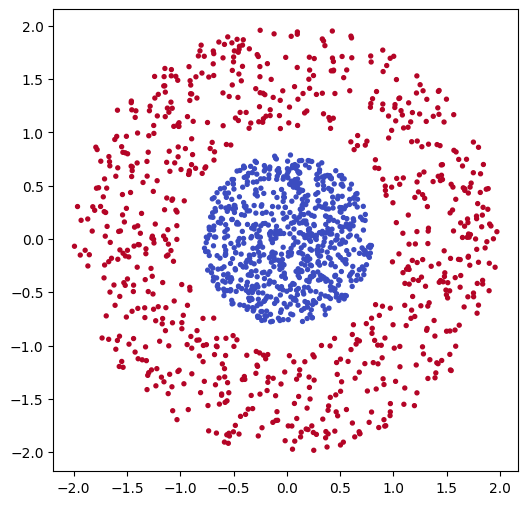

(array([[ 0.64031788, -1.30632847],
        [ 1.52924905, -1.08282996],
        [ 0.33073405,  0.04700536],
        ...,
        [-0.22017999,  1.12789696],
        [-0.45015811,  1.54797643],
        [ 0.3648497 ,  0.13678394]]),
 array([[ 3.28107511e-02, -4.72767451e-01],
        [ 1.22349505e+00,  9.18817988e-01],
        [ 8.52258690e-01, -9.96085155e-01],
        [-4.05400175e-01,  3.41609484e-01],
        [-5.93102200e-01, -3.35693708e-01],
        [-1.64551453e+00, -1.81105082e-01],
        [ 3.57045650e-01,  1.81397245e+00],
        [ 1.12329894e+00, -2.83702040e-01],
        [ 6.10218709e-02, -5.66782870e-02],
        [ 5.54166936e-01, -1.95135956e-01],
        [ 9.90917062e-01, -2.14658418e-01],
        [ 1.77088736e+00,  1.29457753e-04],
        [-1.21552253e+00,  1.15454232e+00],
        [ 3.06032673e-01,  5.96802067e-02],
        [-5.38778220e-01, -1.84889238e+00],
        [ 4.76360605e-01,  3.77225477e-01],
        [ 1.26672574e+00,  8.65519462e-01],
        [-2.79270257e

In [ ]:
sol = Solution1()
sol.create_dataset()
sol.draw_dataset()
sol.split_dataset()

Full report for model A


Model name: A
Parameters amount: 15
Test accuracy: 0.8399999949667188
Model train time: 44.320171274999666




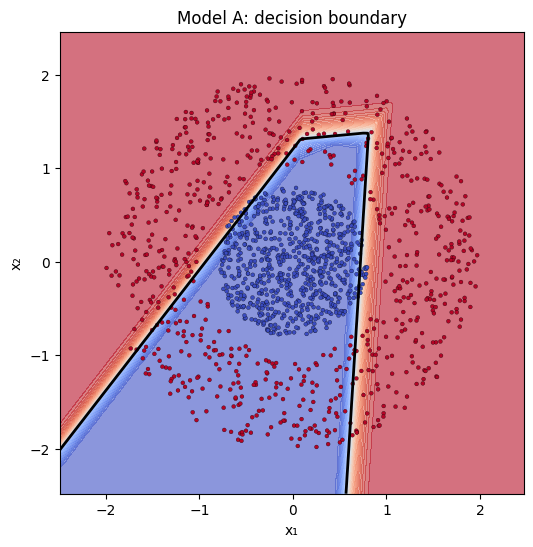

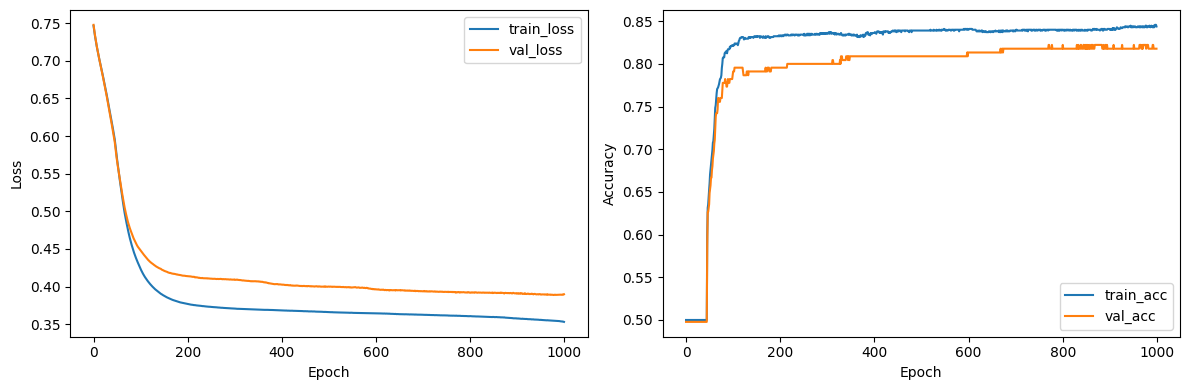

In [ ]:
sol.full_model_stats("A")